**PROJECT TITLE**


FINANCIAL FRAUD DETECTION


**PROBLEM STATEMENT**

**PROPOSED SOLUTION**

**DATASET DESCRIPTION**

**IMPORT LIBRARIES**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

**LOAD DATASET**

In [3]:
df=pd.read_csv("fraud_detection.csv")
df

,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,1,0,Other,79.413607,0.686699,1/1/2022 0:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,9-Aug-24,0
1,1,0,Other,79.413607,0.686699,1/1/2022 0:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,9-Aug-24,0
2,914,0,Other,94.931704,0.856704,2/8/2022 1:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,9-Jan-22,0
3,914,0,Other,94.931704,0.856704,2/8/2022 1:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,9-Jan-22,0
4,294,0,Other,16.922601,0.401233,1/13/2022 5:00,2253,35.151451,1009,Merchant 2253,Location 2253,Customer 1009,32,Address 1009,5359.747810,9-Jan-22,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019,271,1,Other,10.831047,0.620899,1/12/2022 6:00,2611,36.754414,1432,Merchant 2611,Location 2611,Customer 1432,36,Address 1432,5930.219714,8-Mar-23,1
2020,602,0,Retail,28.887068,0.326184,1/26/2022 1:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,27-Jul-23,1
2021,602,0,Retail,28.887068,0.326184,1/26/2022 1:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,27-Jul-23,1
2022,482,0,Food,98.518106,0.706140,1/21/2022 1:00,2584,70.047768,1573,Merchant 2584,Location 2584,Customer 1573,35,Address 1573,8400.252361,27-Jul-23,1


**EDA**

DATASET INSPECTION

In [4]:
df.shape

(2024, 17)

In [5]:
df.dtypes

TransactionID          int64
FraudIndicator         int64
Category              object
TransactionAmount    float64
AnomalyScore         float64
Timestamp             object
MerchantID             int64
Amount               float64
CustomerID             int64
MerchantName          object
Location              object
Name                  object
Age                    int64
Address               object
AccountBalance       float64
LastLogin             object
SuspiciousFlag         int64
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2024 entries, 0 to 2023
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      2024 non-null   int64  
 1   FraudIndicator     2024 non-null   int64  
 2   Category           2024 non-null   object 
 3   TransactionAmount  2024 non-null   float64
 4   AnomalyScore       2024 non-null   float64
 5   Timestamp          2024 non-null   object 
 6   MerchantID         2024 non-null   int64  
 7   Amount             2024 non-null   float64
 8   CustomerID         2024 non-null   int64  
 9   MerchantName       2024 non-null   object 
 10  Location           2024 non-null   object 
 11  Name               2024 non-null   object 
 12  Age                2024 non-null   int64  
 13  Address            2024 non-null   object 
 14  AccountBalance     2024 non-null   float64
 15  LastLogin          2024 non-null   object 
 16  SuspiciousFlag     2024 

In [7]:
df.duplicated().sum()

np.int64(1024)

In [8]:
df.isnull().sum()

TransactionID        0
FraudIndicator       0
Category             0
TransactionAmount    0
AnomalyScore         0
Timestamp            0
MerchantID           0
Amount               0
CustomerID           0
MerchantName         0
Location             0
Name                 0
Age                  0
Address              0
AccountBalance       0
LastLogin            0
SuspiciousFlag       0
dtype: int64

In [9]:
df.columns

Index(['TransactionID', 'FraudIndicator', 'Category', 'TransactionAmount',
       'AnomalyScore', 'Timestamp', 'MerchantID', 'Amount', 'CustomerID',
       'MerchantName', 'Location', 'Name', 'Age', 'Address', 'AccountBalance',
       'LastLogin', 'SuspiciousFlag'],
      dtype='object')

In [10]:
df.select_dtypes(include=['number']).columns.tolist()

['TransactionID',
 'FraudIndicator',
 'TransactionAmount',
 'AnomalyScore',
 'MerchantID',
 'Amount',
 'CustomerID',
 'Age',
 'AccountBalance',
 'SuspiciousFlag']

In [11]:
df.select_dtypes(include=['object']).columns.tolist()

['Category',
 'Timestamp',
 'MerchantName',
 'Location',
 'Name',
 'Address',
 'LastLogin']

In [12]:
for col in df.columns:
    print(f"\n{"="*40}")
    print(f"COLUMN: {col}")
    print(f"{"="*40}")
    print(df[col].value_counts(dropna=False))


COLUMN: TransactionID
TransactionID
187    6
675    6
424    6
701    6
901    6
      ..
996    1
428    1
61     1
339    1
842    1
Name: count, Length: 1000, dtype: int64

COLUMN: FraudIndicator
FraudIndicator
0    1930
1      94
Name: count, dtype: int64

COLUMN: Category
Category
Other     416
Online    411
Travel    404
Food      397
Retail    396
Name: count, dtype: int64

COLUMN: TransactionAmount
TransactionAmount
30.627814    6
76.002999    6
89.105514    6
61.305263    6
41.834161    6
            ..
89.457059    1
20.794809    1
52.224588    1
81.112410    1
97.905023    1
Name: count, Length: 1000, dtype: int64

COLUMN: AnomalyScore
AnomalyScore
0.380487    6
0.953422    6
0.337582    6
0.198231    6
0.716799    6
           ..
0.266778    1
0.633906    1
0.381752    1
0.397371    1
0.169683    1
Name: count, Length: 1000, dtype: int64

COLUMN: Timestamp
Timestamp
1/8/2022 18:00     6
1/29/2022 2:00     6
1/18/2022 15:00    6
1/30/2022 4:00     6
2/7/2022 12:00     6
   

DATA CLEANING

In [13]:
df= df.drop_duplicates()


In [14]:
df.shape

(1000, 17)

In [15]:
df["LastLogin"] = pd.to_datetime(df["LastLogin"])
df

C:\Users\HP\AppData\Local\Temp\ipykernel_15080\746531438.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["LastLogin"] = pd.to_datetime(df["LastLogin"])
C:\Users\HP\AppData\Local\Temp\ipykernel_15080\746531438.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["LastLogin"] = pd.to_datetime(df["LastLogin"])


,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,1,0,Other,79.413607,0.686699,1/1/2022 0:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,2024-08-09,0
2,914,0,Other,94.931704,0.856704,2/8/2022 1:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0
4,294,0,Other,16.922601,0.401233,1/13/2022 5:00,2253,35.151451,1009,Merchant 2253,Location 2253,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0
6,344,0,Other,45.511398,0.337559,1/15/2022 7:00,2238,84.499284,1434,Merchant 2238,Location 2238,Customer 1434,19,Address 1434,1696.877884,2023-03-10,0
7,594,0,Other,10.143275,0.123278,1/25/2022 17:00,2176,22.013210,1796,Merchant 2176,Location 2176,Customer 1796,33,Address 1796,5588.049942,2024-03-06,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017,218,0,Online,21.680778,0.086576,1/10/2022 1:00,2884,84.038218,1387,Merchant 2884,Location 2884,Customer 1387,31,Address 1387,2137.201057,2023-01-22,1
2018,229,0,Other,94.062296,0.258941,1/10/2022 12:00,2687,26.447065,1395,Merchant 2687,Location 2687,Customer 1395,32,Address 1395,4381.287524,2023-01-30,1
2019,271,1,Other,10.831047,0.620899,1/12/2022 6:00,2611,36.754414,1432,Merchant 2611,Location 2611,Customer 1432,36,Address 1432,5930.219714,2023-03-08,1
2020,602,0,Retail,28.887068,0.326184,1/26/2022 1:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,2023-07-27,1


In [16]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors='coerce')
df

C:\Users\HP\AppData\Local\Temp\ipykernel_15080\2524951347.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors='coerce')


,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,1,0,Other,79.413607,0.686699,2022-01-01 00:00:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,2024-08-09,0
2,914,0,Other,94.931704,0.856704,2022-02-08 01:00:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0
4,294,0,Other,16.922601,0.401233,2022-01-13 05:00:00,2253,35.151451,1009,Merchant 2253,Location 2253,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0
6,344,0,Other,45.511398,0.337559,2022-01-15 07:00:00,2238,84.499284,1434,Merchant 2238,Location 2238,Customer 1434,19,Address 1434,1696.877884,2023-03-10,0
7,594,0,Other,10.143275,0.123278,2022-01-25 17:00:00,2176,22.013210,1796,Merchant 2176,Location 2176,Customer 1796,33,Address 1796,5588.049942,2024-03-06,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017,218,0,Online,21.680778,0.086576,2022-01-10 01:00:00,2884,84.038218,1387,Merchant 2884,Location 2884,Customer 1387,31,Address 1387,2137.201057,2023-01-22,1
2018,229,0,Other,94.062296,0.258941,2022-01-10 12:00:00,2687,26.447065,1395,Merchant 2687,Location 2687,Customer 1395,32,Address 1395,4381.287524,2023-01-30,1
2019,271,1,Other,10.831047,0.620899,2022-01-12 06:00:00,2611,36.754414,1432,Merchant 2611,Location 2611,Customer 1432,36,Address 1432,5930.219714,2023-03-08,1
2020,602,0,Retail,28.887068,0.326184,2022-01-26 01:00:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,2023-07-27,1


In [17]:
df['TransactionHour'] = df['Timestamp'].dt.hour
df['TransactionDay'] = df['Timestamp'].dt.dayofweek
df['TransactionMonth'] = df['Timestamp'].dt.month
df

C:\Users\HP\AppData\Local\Temp\ipykernel_15080\3106308193.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['TransactionHour'] = df['Timestamp'].dt.hour
C:\Users\HP\AppData\Local\Temp\ipykernel_15080\3106308193.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['TransactionDay'] = df['Timestamp'].dt.dayofweek
C:\Users\HP\AppData\Local\Temp\ipykernel_15080\3106308193.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_index

,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag,TransactionHour,TransactionDay,TransactionMonth
0,1,0,Other,79.413607,0.686699,2022-01-01 00:00:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,2024-08-09,0,0,5,1
2,914,0,Other,94.931704,0.856704,2022-02-08 01:00:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0,1,1,2
4,294,0,Other,16.922601,0.401233,2022-01-13 05:00:00,2253,35.151451,1009,Merchant 2253,Location 2253,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0,5,3,1
6,344,0,Other,45.511398,0.337559,2022-01-15 07:00:00,2238,84.499284,1434,Merchant 2238,Location 2238,Customer 1434,19,Address 1434,1696.877884,2023-03-10,0,7,5,1
7,594,0,Other,10.143275,0.123278,2022-01-25 17:00:00,2176,22.013210,1796,Merchant 2176,Location 2176,Customer 1796,33,Address 1796,5588.049942,2024-03-06,0,17,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017,218,0,Online,21.680778,0.086576,2022-01-10 01:00:00,2884,84.038218,1387,Merchant 2884,Location 2884,Customer 1387,31,Address 1387,2137.201057,2023-01-22,1,1,0,1
2018,229,0,Other,94.062296,0.258941,2022-01-10 12:00:00,2687,26.447065,1395,Merchant 2687,Location 2687,Customer 1395,32,Address 1395,4381.287524,2023-01-30,1,12,0,1
2019,271,1,Other,10.831047,0.620899,2022-01-12 06:00:00,2611,36.754414,1432,Merchant 2611,Location 2611,Customer 1432,36,Address 1432,5930.219714,2023-03-08,1,6,2,1
2020,602,0,Retail,28.887068,0.326184,2022-01-26 01:00:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,2023-07-27,1,1,2,1


**DATA VISUALIZATION**

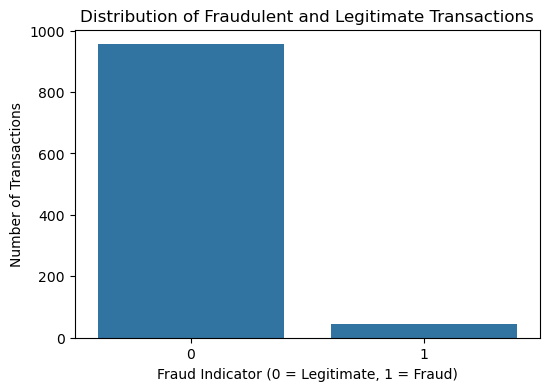

In [18]:
plt.figure(figsize=(6,4))
sns.countplot(x='FraudIndicator', data=df)
plt.title('Distribution of Fraudulent and Legitimate Transactions')
plt.xlabel('Fraud Indicator (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.show()

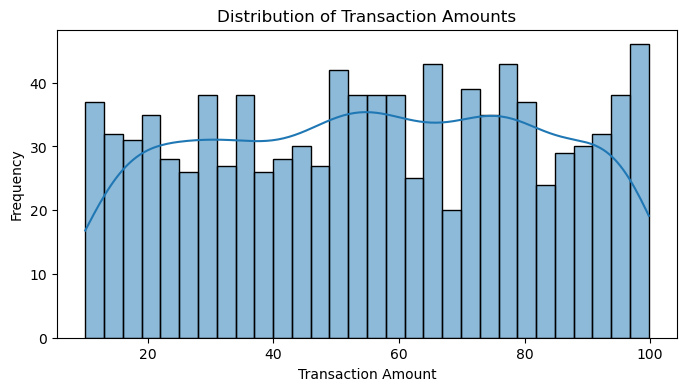

In [19]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x='TransactionAmount', bins=30, kde=True)
plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

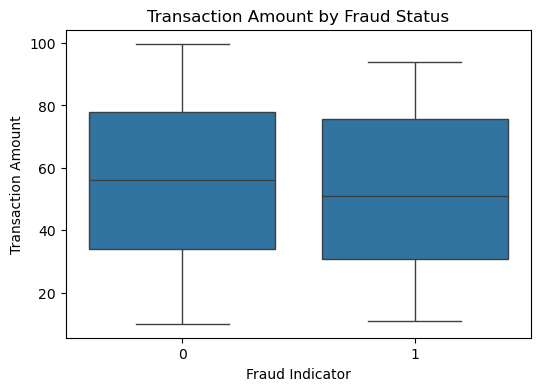

In [20]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='FraudIndicator', y='TransactionAmount')
plt.title('Transaction Amount by Fraud Status')
plt.xlabel('Fraud Indicator') 
plt.ylabel('Transaction Amount')
plt.show()

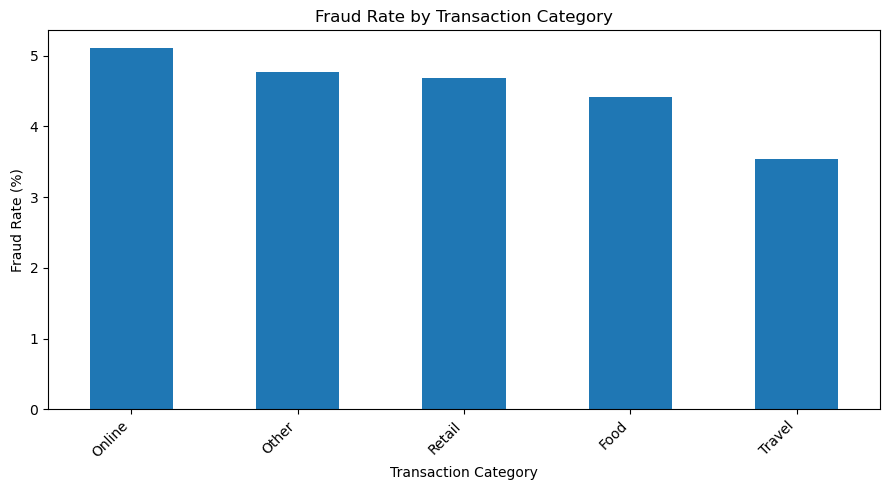

In [21]:
fraud_rate = df.groupby('Category')['FraudIndicator'].mean() * 100
fraud_rate.sort_values(ascending=False).plot(kind='bar', figsize=(9,5))
plt.title('Fraud Rate by Transaction Category')
plt.xlabel('Transaction Category')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**FEATURE ENGINEERING**

In [22]:
encoders = {}

for column in df:
    label_encoder = LabelEncoder()
    df[column] = label_encoder.fit_transform(df[column])
    encoders[column] = label_encoder

C:\Users\HP\AppData\Local\Temp\ipykernel_15080\3065592850.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column] = label_encoder.fit_transform(df[column])
C:\Users\HP\AppData\Local\Temp\ipykernel_15080\3065592850.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column] = label_encoder.fit_transform(df[column])
C:\Users\HP\AppData\Local\Temp\ipykernel_15080\3065592850.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col

**SPLIT DATASET**

**TRAIN MODEL**

**SAVE MODEL**

**CONCLUSION**